In [8]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Load a model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
loaded_model = torch.load("model_shape_prediction.pth")
loaded_model.to(device)

# Load a data as input (phases) to get shapes
phase_input = np.load('phases.npy')

/tmp/ipykernel_8245/2432359938.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_model = torch.load("model_shape_prediction.pth")


In [9]:
type(phase_input)

numpy.ndarray

In [10]:
print(phase_input[:10])

[-5.23598776 -5.68427285 -6.12587861 -0.2800347  -0.71525035 -1.15019534
 -1.58643455 -2.02523595 -2.46864226 -2.91940786]


In [11]:
# Exchange numpy data for torch
phase_input = torch.tensor(phase_input, dtype=torch.float32).to(device)  # Convert to tensor and move to the correct device
print(phase_input)

tensor([-5.2360, -5.6843, -6.1259, -0.2800, -0.7153, -1.1502, -1.5864, -2.0252,
        -2.4686, -2.9194, -3.3701, -3.8209, -4.2804, -4.7437, -5.2096, -5.6766,
        -6.1430, -0.3235, -0.7820, -1.2552, -1.7408, -2.2159, -2.6762, -3.1783,
        -3.6605, -4.1411, -4.6423, -5.1184, -5.6317, -6.1164, -0.3475, -0.8496,
        -1.3496, -1.8734, -2.3839, -2.8868, -3.4195, -3.9501, -4.4790, -5.0091,
        -5.5424, -6.0804, -0.3403, -0.8882, -1.4397, -1.9930, -2.5450, -3.0998,
        -3.6797, -4.2504, -4.8145, -5.4086, -5.9759, -0.3000, -0.8854, -1.4886,
        -2.0995, -2.7063, -3.3150, -3.9302, -4.5599, -5.1916, -5.8351, -0.2048,
        -0.8612, -1.5147, -2.1790, -2.8574, -3.5328, -4.2204, -4.9222, -5.6248,
        -0.0516, -0.7727, -1.5052, -2.2459, -2.9876, -3.7529, -4.5187, -5.3067,
        -6.0979, -0.6183, -1.4378, -2.2705, -3.1068, -3.9755, -4.8460, -5.7342,
        -0.3635, -1.2963, -2.2341, -3.2099, -4.2005, -5.2081, -6.2565, -1.0402,
        -2.1394, -3.2636, -4.4293, -5.64

### Fine! We have prepared everything for filling in
1. Now, we will calculate shapes according vectors off phase dalay
2. For that let's turn on eval mode for prediction model and then will get shapes as output wise-element.
3. Every output will be saved into new vectors - vector of shape coefficients.

In [12]:
print(phase_input.size())
print(phase_input[:10])
print(phase_input.ndim)
print(phase_input.device)

torch.Size([113])
tensor([-5.2360, -5.6843, -6.1259, -0.2800, -0.7153, -1.1502, -1.5864, -2.0252,
        -2.4686, -2.9194], device='cuda:0')
1
cuda:0


In [14]:
# Определяем размеры
num_samples = phase_input.size(0)  # Количество строк (итераций)
output_dim = loaded_model(phase_input[0].unsqueeze(0)).size(0)  # Размер предсказания (второй индекс)

In [15]:
output_dim

2

In [16]:
# Создаем пустую матрицу для хранения результатов
output = torch.zeros((num_samples, output_dim), device=device)

In [17]:
output[:10]

tensor([[0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.]], device='cuda:0')

In [18]:
# Устанавливаем режим оценки
phase_input = phase_input.to(device)
loaded_model.eval()

# Получаем предсказания и заполняем матрицу
with torch.no_grad():
    for i in range(num_samples):
        print(f"Value of phase_input {i} is {phase_input[i]}")
        prediction = loaded_model(phase_input[i].unsqueeze(0))
        print(f"Prediction for {i} is {prediction}")
        output[i] = prediction.squeeze(0)  # Сохраняем строку предсказания

# Проверка выходных данных
print("Выходные данные модели:", output[:10]) # под нулевым индексом в векторе - ширина, под первым индексом - коэффицент а 


Value of phase_input 0 is -5.235987663269043
Prediction for 0 is tensor([-0.2716, -0.3418], device='cuda:0')
Value of phase_input 1 is -5.684272766113281
Prediction for 1 is tensor([-0.5911, -0.8116], device='cuda:0')
Value of phase_input 2 is -6.125878810882568
Prediction for 2 is tensor([-0.8674, -1.2180], device='cuda:0')
Value of phase_input 3 is -0.2800346910953522
Prediction for 3 is tensor([3.6208, 5.1913], device='cuda:0')
Value of phase_input 4 is -0.7152503728866577
Prediction for 4 is tensor([4.9599, 7.3049], device='cuda:0')
Value of phase_input 5 is -1.1501953601837158
Prediction for 5 is tensor([4.6756, 6.9241], device='cuda:0')
Value of phase_input 6 is -1.5864346027374268
Prediction for 6 is tensor([4.0443, 6.0037], device='cuda:0')
Value of phase_input 7 is -2.025235891342163
Prediction for 7 is tensor([3.3754, 5.0215], device='cuda:0')
Value of phase_input 8 is -2.468642234802246
Prediction for 8 is tensor([2.7274, 4.0688], device='cuda:0')
Value of phase_input 9 is -

Готово! Мы создали тензор, который описывает форму ячеек в заданной точке.
Теперь у нас есть форма и есть центры. Осталось пересчитать координаты для атомов в этих точках

In [34]:
width_matrix = []
a_matrix = []

# Разделим вектор на части, будем извлекать элементы.
for i in range (num_samples) :
    width_matrix.append(output[i,0].item())
    a_matrix.append(output[i,1].item())
    
print(width_matrix[:10])
print(a_matrix[:10])

[-0.2716240882873535, -0.5910553932189941, -0.8673849105834961, 3.6207661628723145, 4.959935665130615, 4.675558090209961, 4.0443315505981445, 3.3754091262817383, 2.727415084838867, 2.112229108810425]
[-0.3417704105377197, -0.8115746974945068, -1.2179901599884033, 5.191319465637207, 7.304875373840332, 6.924054145812988, 6.0036516189575195, 5.021496772766113, 4.068836212158203, 3.1641616821289062]


In [43]:
#Начнем заполнение
center_points = np.load('points.npy')
print(center_points[:10])
print(center_points[:,0])

[[ 46.5          0.        ]
 [ 45.21532151   9.89771489]
 [ 41.84277737  19.28983145]
 [ 36.52961067  27.73633724]
 [ 29.51658646  34.83488362]
 [ 21.12903826  40.24103601]
 [ 11.76340688  43.68648621]
 [  1.86972637  44.99418973]
 [ -8.06913841  44.08898784]
 [-17.56024699  41.00415324]]
[ 4.65000000e+01  4.52153215e+01  4.18427774e+01  3.65296107e+01
  2.95165865e+01  2.11290383e+01  1.17634069e+01  1.86972637e+00
 -8.06913841e+00 -1.75602470e+01 -2.61279760e+01 -3.33364145e+01
 -3.88086128e+01 -4.22561690e+01 -4.34908512e+01 -4.24379368e+01
 -3.91428237e+01 -3.37712683e+01 -2.66030793e+01 -1.80149209e+01
 -8.47742536e+00  1.47910838e+00  1.12997714e+01  2.04154068e+01
  2.83055774e+01  3.45016783e+01  3.86195800e+01  4.04218150e+01
  3.97580969e+01  3.66852819e+01  3.13534947e+01  2.41005706e+01
  1.53680291e+01  5.70324419e+00 -4.26769506e+00 -1.38969929e+01
 -2.25347946e+01 -2.95971400e+01 -3.45936711e+01 -3.71653295e+01
 -3.71152999e+01 -3.44291718e+01 -2.92826060e+01 -2.2035086

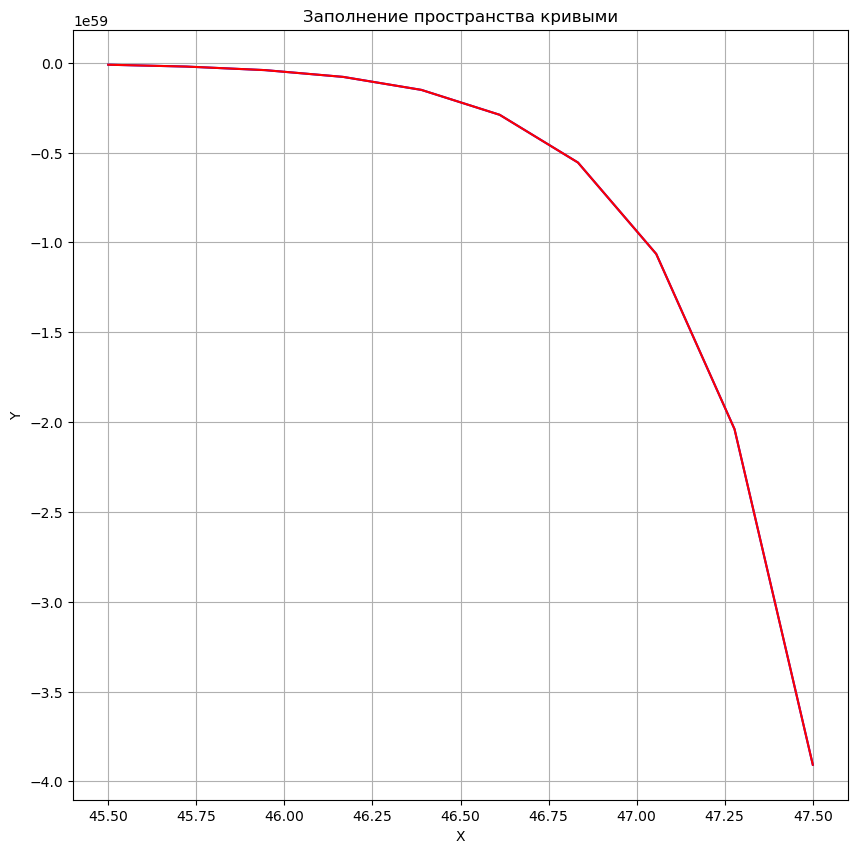

In [50]:
# Параметры цепной линии
x_shift = 1  # диапазон x
num_points = 10  # количество точек

# Создаем график
plt.figure(figsize=(10, 10))

# Next wise-elements operations
for i in range(1):
    x = np.linspace(center_points[i,0] - x_shift, center_points[i,0] + x_shift, num_points)
    y_top = center_points[i,1] + (a_matrix[i] * np.cosh(x / a_matrix[i]))  # верхняя кривая
    y_bottom = center_points[i,1] + (y_top - width_matrix[i]) # нижняя кривая
    
    # Рисуем кривые без замыкания
    plt.plot(x, y_top, color='blue')
    plt.plot(x, y_bottom, color='red')

# Настройки графика
plt.title("Заполнение пространства кривыми")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.show()

Пока получаем лажу так как имеем отрицательные значения коэффицентов. Нужно переобучить модель.